Importar librerias

In [15]:
import os
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Configurar estilo visual de las gráficas
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)



Cargar dataset y describirlo

In [16]:
# Cargar dataset
data_url = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
)
column_names = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal",
    "target",
]
# Leerlo
df = pd.read_csv(data_url, names=column_names, na_values="?")


print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.")
print("\n--- Estructura y tipos de datos iniciales ---")
print(df.info())

print("\n--- Primeros 5 registros ---")
display(df.head())

Dimensiones del dataset: 303 filas y 14 columnas.

--- Estructura y tipos de datos iniciales ---
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB
None

--- Primeros 5 registros ---


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Análisis Exploratorio de Datos (EDA)

,age,trestbps,chol,thalach,oldpeak
count,303.00,303.00,303.00,303.00,303.00
mean,54.44,131.69,246.69,149.61,1.04
std,9.04,17.60,51.78,22.88,1.16
min,29.00,94.00,126.00,71.00,0.00
25%,48.00,120.00,211.00,133.50,0.00
50%,56.00,130.00,241.00,153.00,0.80
75%,61.00,140.00,275.00,166.00,1.60
max,77.00,200.00,564.00,202.00,6.20


/var/folders/_0/ysw73r991bz89csmnpb5171c0000gn/T/ipykernel_2735/1341217240.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="target", data=df, palette="crest")


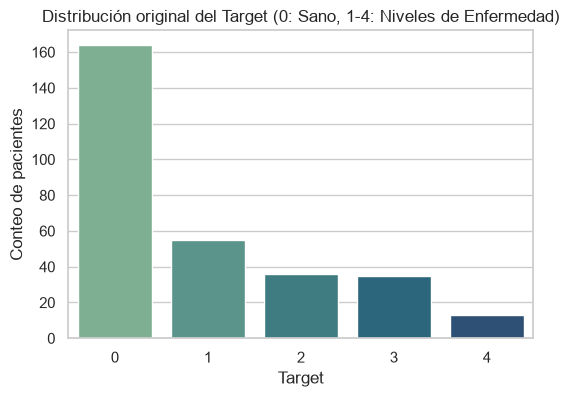

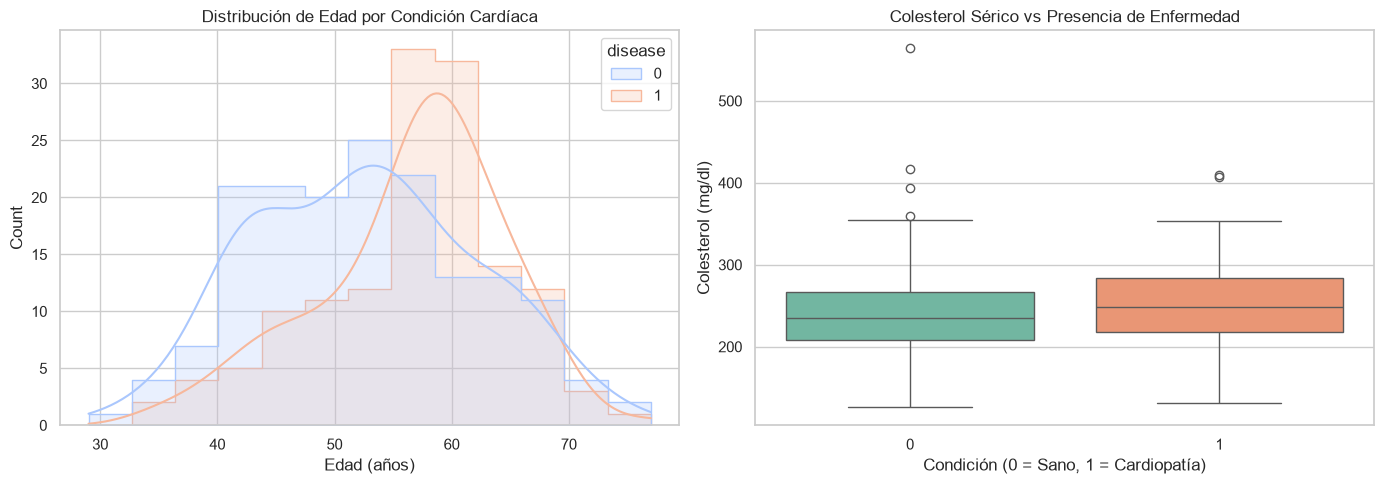

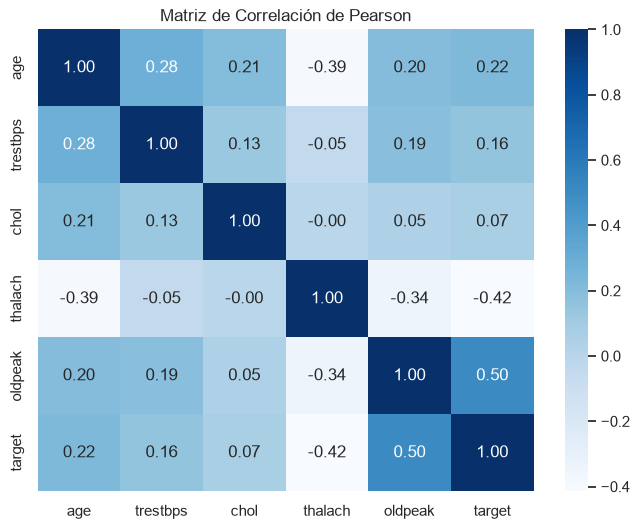

In [17]:
display(
    df[["age", "trestbps", "chol", "thalach", "oldpeak"]].describe().round(2)
)
plt.figure(figsize=(6, 4))
sns.countplot(x="target", data=df, palette="crest")
plt.title("Distribución original del Target (0: Sano, 1-4: Niveles de Enfermedad)")
plt.xlabel("Target")
plt.ylabel("Conteo de pacientes")
plt.show()
df_temp = df.copy()
df_temp["disease"] = df_temp["target"].apply(
    lambda x: 1 if x > 0 else 0
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(
    data=df_temp,
    x="age",
    hue="disease",
    kde=True,
    ax=axes[0],
    palette="coolwarm",
    element="step",
)
axes[0].set_title("Distribución de Edad por Condición Cardíaca")
axes[0].set_xlabel("Edad (años)")

sns.boxplot(
    data=df_temp,
    x="disease",
    y="chol",
    ax=axes[1],
    palette="Set2",
    hue="disease",
    legend=False,
)
axes[1].set_title("Colesterol Sérico vs Presencia de Enfermedad")
axes[1].set_xlabel("Condición (0 = Sano, 1 = Cardiopatía)")
axes[1].set_ylabel("Colesterol (mg/dl)")
plt.tight_layout()
plt.show()
# Matriz de correlación
plt.figure(figsize=(8, 6))
sns.heatmap(
    df[["age", "trestbps", "chol", "thalach", "oldpeak", "target"]].corr(),
    annot=True,
    cmap="Blues",
    fmt=".2f",
)
plt.title("Matriz de Correlación de Pearson")
plt.show()

Limpieza y Calidad de Datos

In [18]:
df_clean = df.copy()
#valores nulos

null_counts = df_clean.isnull().sum()
print("Valores nulos identificados por columna:")
print(null_counts[null_counts > 0])
#'ca' y 'thal' tienen nulos
df_clean["ca"] = df_clean["ca"].fillna(df_clean["ca"].mode()[0])
df_clean["thal"] = df_clean["thal"].fillna(df_clean["thal"].mode()[0])

# 2. Duplicados
dups = df_clean.duplicated().sum()
print(f"\nRegistros duplicados encontrados: {dups}")
if dups > 0:
  df_clean = df_clean.drop_duplicates()



df_clean["target"] = df_clean["target"].apply(lambda x: 1 if x > 0 else 0)

#outliers
q1_chol = df_clean["chol"].quantile(0.25)
q3_chol = df_clean["chol"].quantile(0.75)
iqr_chol = q3_chol - q1_chol
limite_sup_chol = q3_chol + 3.0 * iqr_chol
outliers_chol = (df_clean["chol"] > limite_sup_chol).sum()
print(
    f"Outliers extremos detectados en colesterol (> {limite_sup_chol:.1f}"
    f" mg/dl): {outliers_chol}"
)
print(
    "\nLimpieza finalizada. Dataset limpio listo con",
    df_clean.shape[0],
    "filas y",
    df_clean.shape[1],
    "columnas.",
)

Valores nulos identificados por columna:
ca      4
thal    2
dtype: int64

Registros duplicados encontrados: 0
Outliers extremos detectados en colesterol (> 467.0 mg/dl): 1

Limpieza finalizada. Dataset limpio listo con 303 filas y 14 columnas.


Modelo Base, Evaluación y Registro en MLflow

In [19]:
#División de variables
X = df_clean.drop(columns=["target"])
y = df_clean["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
# Configuración y ejecución del experimento en MLflow
mlflow.set_experiment("Heart_Disease_Baseline")
with mlflow.start_run(run_name="logistic_regression_baseline") as run:

  # Parámetros del modelo y preprocesamiento
  params = {
      "model_type": "LogisticRegression",
      "solver": "liblinear",
      "C": 1.0,
      "max_iter": 500,
      "test_size": 0.25,
      "random_state": 42,
      "scaler": "StandardScaler",
  }
  mlflow.log_params(params)

  scaler = StandardScaler()
  X_train_scaled = scaler.fit_transform(X_train)
  X_test_scaled = scaler.transform(X_test)

  # Entrenamiento del Baseline
  model = LogisticRegression(
      solver=params["solver"],
      C=params["C"],
      max_iter=params["max_iter"],
      random_state=params["random_state"],
  )
  model.fit(X_train_scaled, y_train)

  # Evaluar
  y_pred = model.predict(X_test_scaled)
  y_proba = model.predict_proba(X_test_scaled)[:, 1]

  acc = accuracy_score(y_test, y_pred)
  prec = precision_score(y_test, y_pred)
  rec = recall_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)
  auc = roc_auc_score(y_test, y_proba)

  metrics = {
      "accuracy": acc,
      "precision": prec,
      "recall": rec,
      "f1_score": f1,
      "roc_auc": auc,
  }
  mlflow.log_metrics(metrics)

  # Generar y registrar el artefacto visual (Matriz de Confusión)
  cm = confusion_matrix(y_test, y_pred)
  plt.figure(figsize=(5, 4))
  sns.heatmap(
      cm,
      annot=True,
      fmt="d",
      cmap="Reds",
      xticklabels=["Sano", "Cardiopatía"],
      yticklabels=["Sano", "Cardiopatía"],
  )
  plt.ylabel("Etiqueta Real")
  plt.xlabel("Etiqueta Predicha")
  plt.title("Matriz de Confusión - Baseline")
  cm_filename = "confusion_matrix.png"
  plt.savefig(cm_filename, bbox_inches="tight")
  plt.close()

  mlflow.log_artifact(cm_filename)
  if os.path.exists(cm_filename):
    os.remove(cm_filename)

  # Registro del modelo como artefacto serializado
  mlflow.sklearn.log_model(model, artifact_path="model")

  print("=== Experimento registrado en MLflow con éxito ===")
  print(f"Run ID: {run.info.run_id}")
  print("\nMétricas de evaluación:")
  for k, v in metrics.items():
    print(f"  * {k}: {v:.4f}")

2026/10/04 23:34:48 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


=== Experimento registrado en MLflow con éxito ===
Run ID: 30c0489f42ed4f2da154b3c1d1d9c9a7

Métricas de evaluación:
  * accuracy: 0.8684
  * precision: 0.8378
  * recall: 0.8857
  * f1_score: 0.8611
  * roc_auc: 0.9310


Interpretación de la evaluacion

El modelo base de Regresión Logística evaluado sobre el conjunto de prueba 
independiente (76 pacientes) arrojó las siguientes métricas de desempeño:
  * accuracy: 0.8684
  * precision: 0.8378
  * recall: 0.8857
  * f1_score: 0.8611
  * roc_auc: 0.9310

En un sistema de diagnóstico asistido para cardiopatías, la métrica crítica de negocio y seguridad médica es el **Recall** de la clase positiva (presencia de enfermedad cardíaca). Un falso negativo representa a un paciente enfermo que es clasificado erróneamente como sano y dado de alta sin intervención oportuna, lo cual conlleva riesgos médicos severos.
El modelo base alcanza un **Recall del 88.57%**, lo que indica que detecta correctamente a casi 9 de cada 10 pacientes con afección cardíaca en datos no vistos, manteniendo al mismo tiempo una **Precisión sólida del 83.78%** que evita saturar el sistema con excesivos falsos positivos.
Asimismo, el valor de **ROC-AUC de 0.9310** demuestra una capacidad de discriminación probabilística sobresaliente entre clases, confirmando que la separación entre pacientes sanos y enfermos es robusta incluso con un clasificador lineal estándar.
Este desempeño establece una línea base sólida y competitiva. Para iteraciones futuras, el margen de mejora se centrará en técnicas de calibración de umbrales y arquitecturas más complejas orientadas a cerrar la brecha del 11.43% restante de falsos negativos sin degradar la precisión.



Reflexión

Al concluir este ejercicio, reconozco que el flujo desarrollado dentro de un notebook representa únicamente una etapa exploratoria y experimental, la cual resulta sumamente frágil e insuficiente si quisiéramos llevar este modelo a un entorno clínico real. Para transformar este prototipo en un sistema robusto, considero fundamental adoptar prácticas formales de MLOps. En primer lugar, desacoplaría el código en módulos independientes y reproducibles, orquestados mediante pipelines automatizados y con un estricto control de versiones de datos usando herramientas como  Git, garantizando así un linaje claro ante cualquier auditoría. Estas herramientas me ayudarian a tener un mejor control y un sistema mas robusto.

Dentro de mi área profesional, estos aprendizajes cobran un sentido tangible: en entornos transaccionales de misión crítica y alta disponibilidad, ningún componente de software se promueve a producción sin telemetría exhaustiva, observabilidad continua, control riguroso de versiones y acuerdos de nivel de servicio claros. MLOps traslada esa misma disciplina operativa al aprendizaje automático, permitiendo que dejemos atrás los scripts manuales y tratemos a los modelos predictivos como servicios resilientes, estables, auditables y alineados con los más altos estándares de confiabilidad de la ingeniería de software.
